# Phase 6 — ความเสี่ยงและการทดสอบสถานการณ์

## 1. เริ่มจากพอร์ต Equal Weight

ไฟล์ equity curve จาก Phase 5 บอกว่าเงินเริ่มต้น 1 บาทมีมูลค่าเท่าไรในแต่ละวัน เราหารมูลค่าวันนี้ด้วยมูลค่าวันก่อนแล้วลบ 1 เพื่อกลับเป็นผลตอบแทนรายวันหลังค่าธรรมเนียม วันแรกใช้ 1 บาทเป็นมูลค่าก่อนเริ่มทดสอบ

In [1]:
from pathlib import Path

import pandas as pd

cwd = Path.cwd()
equity_path = next(
    path / "outputs" / "equity_curves.csv"
    for path in (cwd, cwd.parent, cwd / "Thai_Equity_Portfolio")
    if (path / "outputs" / "equity_curves.csv").is_file()
)
equity = pd.read_csv(equity_path, parse_dates=["date"], index_col="date").sort_index()
ew_wealth = equity["EW"]
previous_wealth = ew_wealth.shift(1, fill_value=1.0)
ew_returns = ew_wealth / previous_wealth - 1

print(f"Equal Weight หลังหักค่าธรรมเนียม | {len(ew_returns):,} วันซื้อขาย")
display(pd.DataFrame({
    "มูลค่าวันก่อน (บาท)": previous_wealth,
    "มูลค่าวันนี้ (บาท)": ew_wealth,
    "ผลตอบแทนวันนี้ (%)": ew_returns * 100,
}).head(3).round(4))

Equal Weight หลังหักค่าธรรมเนียม | 1,700 วันซื้อขาย


,มูลค่าวันก่อน (บาท),มูลค่าวันนี้ (บาท),ผลตอบแทนวันนี้ (%)
date,,,
2018-01-03,1.0000,1.0135,1.3483
2018-01-04,1.0135,1.0196,0.6013
2018-01-05,1.0196,1.0163,-0.3260


## 2. Historical VaR 95% สำหรับหนึ่งวัน

เรียงผลตอบแทนจากแย่สุดไปดีที่สุด แล้วมองหาเส้นแบ่งฝั่ง 5% วันที่แย่ที่สุด เราใช้ quantile 5% ของผลตอบแทน ดังนั้นค่าที่เส้นแบ่งมักติดลบ ส่วนที่รายงานเป็น VaR คือขนาดของการขาดทุน จึงกลับเครื่องหมายให้เป็นบวก

ตารางแรกแสดงวันที่ขาดทุนหนักสุด ตารางที่สองแสดงวันรอบเส้นแบ่งเพื่อให้เห็นว่าค่า VaR อยู่ตรงไหน เมื่อ quantile ตกอยู่ระหว่างสองอันดับ pandas ประมาณค่าระหว่างผลตอบแทนของสองอันดับนั้น

In [2]:
from math import ceil, floor

tail_probability = 0.05
sorted_returns = ew_returns.sort_values()
cutoff = sorted_returns.quantile(tail_probability)
var_95 = -cutoff

# pandas ใช้ตำแหน่งฐาน 0 ในการประมาณ quantile ระหว่างสองอันดับ
position = (len(sorted_returns) - 1) * tail_probability
bottom, top = floor(position), ceil(position)
ranked = sorted_returns.mul(100).rename("ผลตอบแทน (%)").reset_index()
ranked.index = pd.RangeIndex(1, len(ranked) + 1, name="อันดับจากแย่สุด")

print("วันที่แย่ที่สุด 5 วัน")
display(ranked.head(5).round({"ผลตอบแทน (%)": 4}))
print(f"สองอันดับรอบเส้นแบ่ง 5% (อันดับ {bottom + 1} และ {top + 1})")
display(ranked.iloc[bottom:top + 1].round({"ผลตอบแทน (%)": 4}))
print(f"เส้นแบ่งผลตอบแทน = {cutoff:.4%}")
print(f"Historical VaR 95% สำหรับหนึ่งวัน = {var_95:.4%}")
print(f"จำนวนวันที่ขาดทุนเกิน VaR ในช่วงนี้ = {(ew_returns < cutoff).sum()} วัน")

วันที่แย่ที่สุด 5 วัน


,date,ผลตอบแทน (%)
อันดับจากแย่สุด,,
1,2020-03-12,-11.7300
2,2020-03-23,-10.2011
3,2020-03-16,-8.2897
4,2020-03-09,-8.1813
5,2020-02-26,-5.5033


สองอันดับรอบเส้นแบ่ง 5% (อันดับ 85 และ 86)


,date,ผลตอบแทน (%)
อันดับจากแย่สุด,,
85,2019-03-25,-1.3046
86,2021-11-29,-1.3022


เส้นแบ่งผลตอบแทน = -1.3023%
Historical VaR 95% สำหรับหนึ่งวัน = 1.3023%
จำนวนวันที่ขาดทุนเกิน VaR ในช่วงนี้ = 85 วัน


**ลองอ่านตาราง** เปรียบเทียบวันขาดทุนหนักสุดกับค่า VaR พอร์ตเคยขาดทุนเกินเส้นแบ่งนี้มากแค่ไหน? เมื่อแยกความหมายของสองตัวเลขนี้ได้แล้ว ขั้นถัดไปคือ CVaR ซึ่งดูผลขาดทุนเฉลี่ยในกลุ่มวันแย่ ๆ

## 3. Historical CVaR 95% สำหรับหนึ่งวัน

VaR ให้เส้นแบ่งของกลุ่มวันขาดทุนหนัก ส่วน CVaR หาค่าเฉลี่ยของผลขาดทุนในกลุ่มนั้น เราเลือกทุกวันที่ผลตอบแทนต่ำกว่าหรือเท่ากับเส้นแบ่ง VaR ในข้อมูลนี้ได้ 85 วัน แล้วกลับเครื่องหมายของผลตอบแทนเฉลี่ยเพื่อรายงานเป็นขนาดของการขาดทุน

ตารางแรกแสดงบางวันจากกลุ่ม 85 วัน ทั้งวันแย่ที่สุดและวันที่อยู่ใกล้เส้นแบ่ง ตารางที่สองวาง VaR กับ CVaR คู่กันเพื่ออ่านความต่าง

In [3]:
tail_returns = sorted_returns.loc[sorted_returns <= cutoff]
cvar_95 = -tail_returns.mean()

print(f"วันในกลุ่มที่ใช้คำนวณ CVaR: {len(tail_returns)} จาก {len(ew_returns):,} วัน")
tail_preview = pd.concat([tail_returns.head(3), tail_returns.tail(3)])
display((tail_preview * 100).round(4).to_frame("ผลตอบแทน (%)"))
print(f"ผลตอบแทนเฉลี่ยของทั้ง {len(tail_returns)} วัน = {tail_returns.mean():.4%}")

risk_summary = pd.DataFrame({
    "ขนาดการขาดทุน (%)": [var_95 * 100, cvar_95 * 100],
    "ความหมาย": ["เส้นแบ่งกลุ่มวันที่แย่ที่สุด 5%", "ขาดทุนเฉลี่ยในกลุ่มวันที่แย่ที่สุด 5%"],
}, index=pd.Index(["Historical VaR 95%", "Historical CVaR 95%"], name="ตัววัด"))
display(risk_summary.round(4))

วันในกลุ่มที่ใช้คำนวณ CVaR: 85 จาก 1,700 วัน


,ผลตอบแทน (%)
date,
2020-03-12,-11.7300
2020-03-23,-10.2011
2020-03-16,-8.2897
2021-01-18,-1.3494
2020-07-24,-1.3385
2019-03-25,-1.3046


ผลตอบแทนเฉลี่ยของทั้ง 85 วัน = -2.4617%


,ขนาดการขาดทุน (%),ความหมาย
ตัววัด,,
Historical VaR 95%,1.3023,เส้นแบ่งกลุ่มวันที่แย่ที่สุด 5%
Historical CVaR 95%,2.4617,ขาดทุนเฉลี่ยในกลุ่มวันที่แย่ที่สุด 5%


## 4. Historical Stress Test ช่วง COVID-19

ลองเริ่มด้วยเงิน **100 บาท** ก่อนวันซื้อขายแรกของช่วง **ก.พ.–มี.ค. 2020** แล้วใช้ผลตอบแทนรายวันหลังค่าธรรมเนียมของพอร์ต Equal Weight จาก backtest เดิม

- **ผลตอบแทนทั้งช่วง** บอกว่าเงินปลายทางเปลี่ยนไปกี่เปอร์เซ็นต์จาก 100 บาท
- **Max Drawdown ในช่วง** บอกว่าระหว่างทางพอร์ตเคยลดลงจากจุดสูงสุดที่เห็นถึงตอนนั้นลึกเท่าไร เรานับทุนตั้งต้น 100 บาทเป็นจุดอ้างอิงด้วย

ตัวเลขทั้งสองอาจต่างกัน เพราะพอร์ตอาจฟื้นบางส่วนก่อนวันสุดท้าย

ทดสอบ 2020-02-03 ถึง 2020-03-31


,ผลของ Equal Weight
ตัววัด,
วันซื้อขายในช่วง,41 วัน
เงินตั้งต้น,100.00 บาท
เงินปลายทาง,74.98 บาท
ผลตอบแทนทั้งช่วง,-25.02%
Max Drawdown ในช่วง,-34.85%
วันที่พอร์ตทำยอดก่อนลงลึกสุด,2020-02-07
วันที่ลงจากยอดลึกสุด,2020-03-23


ตัวอย่างเส้นทางของเงิน: ราคาฐาน วันแรก ยอดก่อนตก จุดต่ำสุด และวันสุดท้าย


,ผลตอบแทนรายวัน (%),มูลค่าพอร์ต (บาท),ยอดสูงสุดถึงวันนั้น (บาท),Drawdown (%)
date,,,,
2020-01-31,NaN,100.0000,100.0000,0.0000
2020-02-03,-1.4029,98.5971,100.0000,-1.4029
2020-02-07,0.2298,101.8687,101.8687,0.0000
2020-03-23,-10.2011,66.3653,101.8687,-34.8522
2020-03-31,3.8220,74.9808,101.8687,-26.3946


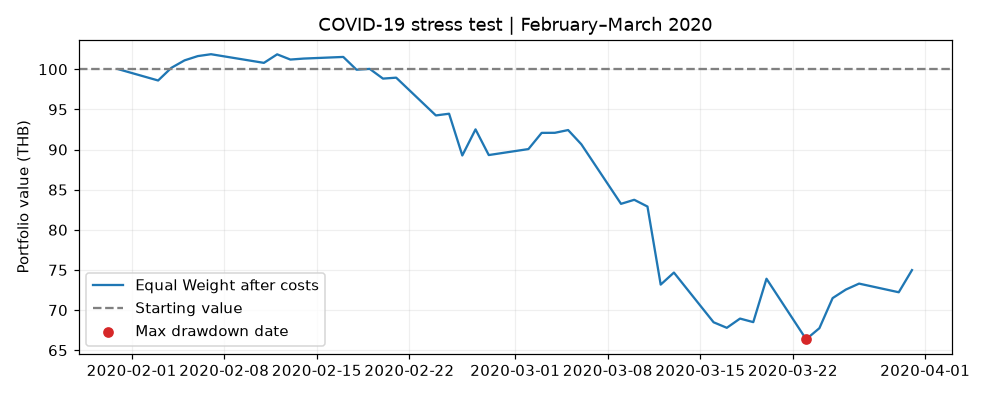

In [4]:
import matplotlib.pyplot as plt

stress_returns = ew_returns.loc["2020-02-01":"2020-03-31"]
initial_wealth = 100.0
before_stress = ew_returns.index[ew_returns.index < stress_returns.index[0]][-1]
stress_wealth = pd.concat([
    pd.Series([initial_wealth], index=[before_stress]),
    initial_wealth * (1 + stress_returns).cumprod(),
]).rename_axis("date")

running_peak = stress_wealth.cummax()
stress_drawdown = stress_wealth / running_peak - 1
trough_date = stress_drawdown.idxmin()
peak_date = stress_wealth.loc[:trough_date].idxmax()
ending_wealth = stress_wealth.iloc[-1]
period_return = ending_wealth / initial_wealth - 1
max_drawdown = stress_drawdown.loc[trough_date]

stress_summary = pd.DataFrame([
    ("วันซื้อขายในช่วง", f"{len(stress_returns)} วัน"),
    ("เงินตั้งต้น", f"{initial_wealth:.2f} บาท"),
    ("เงินปลายทาง", f"{ending_wealth:.2f} บาท"),
    ("ผลตอบแทนทั้งช่วง", f"{period_return:.2%}"),
    ("Max Drawdown ในช่วง", f"{max_drawdown:.2%}"),
    ("วันที่พอร์ตทำยอดก่อนลงลึกสุด", f"{peak_date:%Y-%m-%d}"),
    ("วันที่ลงจากยอดลึกสุด", f"{trough_date:%Y-%m-%d}"),
], columns=["ตัววัด", "ผลของ Equal Weight"])

print(f"ทดสอบ {stress_returns.index[0]:%Y-%m-%d} ถึง {stress_returns.index[-1]:%Y-%m-%d}")
display(stress_summary.set_index("ตัววัด"))

print("ตัวอย่างเส้นทางของเงิน: ราคาฐาน วันแรก ยอดก่อนตก จุดต่ำสุด และวันสุดท้าย")
stress_preview = pd.DataFrame({
    "ผลตอบแทนรายวัน (%)": stress_returns * 100,
    "มูลค่าพอร์ต (บาท)": stress_wealth,
    "ยอดสูงสุดถึงวันนั้น (บาท)": running_peak,
    "Drawdown (%)": stress_drawdown * 100,
})
key_dates = pd.DatetimeIndex([
    before_stress, stress_returns.index[0], peak_date, trough_date, stress_returns.index[-1],
]).unique().sort_values()
display(stress_preview.loc[key_dates].round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(stress_wealth.index, stress_wealth, label="Equal Weight after costs")
ax.axhline(initial_wealth, color="0.5", linestyle="--", label="Starting value")
ax.scatter(trough_date, stress_wealth.loc[trough_date], color="tab:red", zorder=3, label="Max drawdown date")
ax.set(title="COVID-19 stress test | February–March 2020", ylabel="Portfolio value (THB)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Paired Block Bootstrap ของส่วนต่าง Sharpe

เราจะดูว่า **Sharpe ของ Equal Weight ลบ Sharpe ของ TDEX** เปลี่ยนได้แค่ไหนเมื่อสุ่มช่วงวันซื้อขายจากข้อมูลเดิม จุดสำคัญคือ **หยิบวันของทั้งสองพอร์ตพร้อมกัน** เพื่อให้ทั้งคู่เจอตลาดวันเดียวกัน

### 5.1 ดูการต่อบล็อกเพียงรอบเดียว

ลองใช้ข้อมูล 8 วันแรกก่อน และกำหนดจุดเริ่มบล็อกเองเพื่อให้ไล่ตารางง่าย แต่ละบล็อกหยิบ 3 แถวติดกัน บล็อกหนึ่งอาจถูกหยิบซ้ำได้ เมื่อเอามาต่อกันแล้วตัดให้เหลือ 8 แถวเท่าชุดเดิม

In [5]:
import numpy as np

paired_returns = (equity[["EW", "Benchmark"]]
                  / equity[["EW", "Benchmark"]].shift(1, fill_value=1.0) - 1)
paired_returns = paired_returns.rename(columns={"Benchmark": "TDEX"})
assert np.allclose(paired_returns["EW"], ew_returns)


def block_positions(starts, block_length, sample_size):
    return (starts[..., None] + np.arange(block_length)).reshape(
        *starts.shape[:-1], -1
    )[..., :sample_size]


example = paired_returns.head(8)
print("ข้อมูลจริง 8 วันแรกก่อนนำมาจัดใหม่ (%)")
display((example * 100).round(4))

example_block_length = 3
example_starts = np.array([2, 0, 2])  # ตำแหน่งเริ่มต้นนับจาก 0
positions = block_positions(example_starts, example_block_length, len(example))
one_sample = (example.iloc[positions] * 100).round(4).reset_index()
one_sample.insert(0, "บล็อก", np.arange(len(one_sample)) // example_block_length + 1)
one_sample.index = pd.RangeIndex(1, len(one_sample) + 1, name="ลำดับใหม่")
print("เลือกบล็อกที่เริ่มจากแถว 3 → แถว 1 → แถว 3 แล้วต่อกัน (%)")
print("ถ้าวันไหนปรากฏซ้ำ ทั้ง EW และ TDEX จะซ้ำพร้อมกัน เพราะใช้ผลตอบแทนของวันเดียวกัน")
display(one_sample)


ข้อมูลจริง 8 วันแรกก่อนนำมาจัดใหม่ (%)


,EW,TDEX
date,,
2018-01-03,1.3483,1.8733
2018-01-04,0.6013,1.0508
2018-01-05,-0.3260,0.1733
2018-01-08,-0.2144,-0.0865
2018-01-09,0.1204,0.0866
2018-01-10,-0.0599,-0.0865
2018-01-11,0.0244,0.3463
2018-01-12,0.3286,0.4314


เลือกบล็อกที่เริ่มจากแถว 3 → แถว 1 → แถว 3 แล้วต่อกัน (%)
ถ้าวันไหนปรากฏซ้ำ ทั้ง EW และ TDEX จะซ้ำพร้อมกัน เพราะใช้ผลตอบแทนของวันเดียวกัน


,บล็อก,date,EW,TDEX
ลำดับใหม่,,,,
1,1,2018-01-05,-0.3260,0.1733
2,1,2018-01-08,-0.2144,-0.0865
3,1,2018-01-09,0.1204,0.0866
4,2,2018-01-03,1.3483,1.8733
5,2,2018-01-04,0.6013,1.0508
6,2,2018-01-05,-0.3260,0.1733
7,3,2018-01-05,-0.3260,0.1733
8,3,2018-01-08,-0.2144,-0.0865


### 5.2 สุ่มซ้ำด้วยข้อมูลจริง

ในแต่ละรอบ สุ่มวันเริ่มต้นของบล็อกขนาด **20 วันซื้อขายติดกัน** แบบคืนตัวอย่าง จากนั้นต่อบล็อกจนได้ **1,700 แถว** คำนวณ Sharpe ของทั้งสองพอร์ตโดยใช้ risk-free rate **2.5% ต่อปี** ตาม Phase 5 แล้วเก็บส่วนต่างไว้หนึ่งค่า

ทำทั้งหมด **2,000 รอบ** เพื่อสร้างช่วงความเชื่อมั่น 95% แบบ percentile ใช้ quantile **2.5% และ 97.5%** ของส่วนต่างที่สุ่มได้ ความยาวบล็อก 20 วันเป็นสมมติฐานของการทดลองนี้ ช่วงที่ได้สะท้อนความไม่แน่นอนจากข้อมูลย้อนหลังภายใต้สมมติฐานนี้

สุ่ม 2,000 รอบ | รอบละ 85 บล็อก × 20 วัน | ใช้ 1,700 แถวต่อรอบ
5 รอบแรก แต่ละแถวให้ส่วนต่าง Sharpe หนึ่งค่า


,Sharpe EW,Sharpe TDEX,ส่วนต่าง EW − TDEX
รอบ,,,
1,0.3175,-0.1109,0.4284
2,0.0581,-0.1247,0.1829
3,1.0078,0.6072,0.4006
4,0.1547,0.0108,0.1440
5,-0.1050,-0.2010,0.0960


นำส่วนต่างทั้ง 2,000 ค่ามาหาช่วงความเชื่อมั่น


,ค่า Sharpe หรือส่วนต่าง
Sharpe EW จากข้อมูลจริง,0.2470
Sharpe TDEX จากข้อมูลจริง,0.0196
ส่วนต่างจากข้อมูลจริง,0.2274
ขอบล่าง CI 95%,-0.0565
ขอบบน CI 95%,0.5583


ช่วงคร่อม 0 → ข้อมูลยังไม่ชี้ชัดว่า EW หรือ TDEX มี Sharpe สูงกว่า


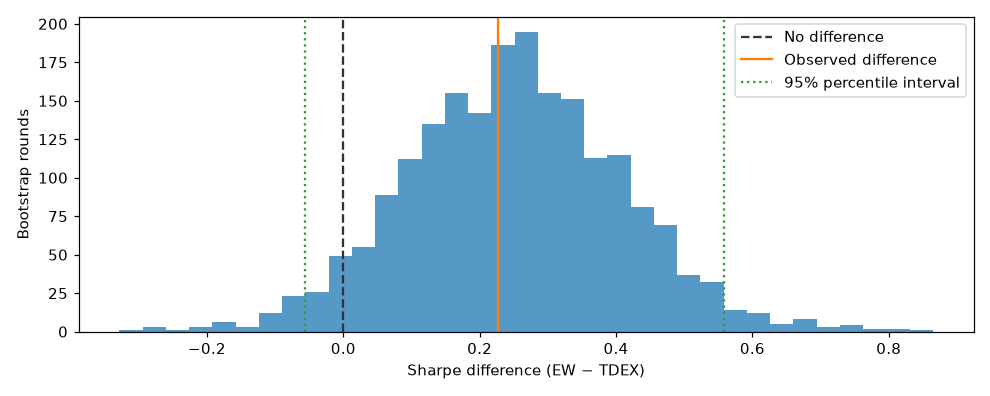

In [6]:
block_length = 20
n_rounds = 2000
days_per_year = 252
risk_free_rate = 0.025

values = paired_returns.to_numpy()
n_days = len(values)
n_blocks = (n_days + block_length - 1) // block_length
rng = np.random.default_rng(42)
starts = rng.integers(0, n_days - block_length + 1, size=(n_rounds, n_blocks))
sample_indices = block_positions(starts, block_length, n_days)
samples = values[sample_indices]  # รอบ × วัน × พอร์ต ใช้ index เดียวกันสำหรับทั้งสองพอร์ต


def annualized_sharpe(daily_returns):
    annual_return = daily_returns.mean(axis=-2) * days_per_year
    annual_vol = daily_returns.std(axis=-2, ddof=1) * np.sqrt(days_per_year)
    return (annual_return - risk_free_rate) / annual_vol


observed = annualized_sharpe(values)
observed_diff = observed[0] - observed[1]
boot_sharpe = annualized_sharpe(samples)
boot_diff = boot_sharpe[:, 0] - boot_sharpe[:, 1]
low, high = np.quantile(boot_diff, [0.025, 0.975])

print(f"สุ่ม {n_rounds:,} รอบ | รอบละ {n_blocks} บล็อก × {block_length} วัน | ใช้ {n_days:,} แถวต่อรอบ")
print("5 รอบแรก แต่ละแถวให้ส่วนต่าง Sharpe หนึ่งค่า")
bootstrap_preview = pd.DataFrame({
    "Sharpe EW": boot_sharpe[:5, 0],
    "Sharpe TDEX": boot_sharpe[:5, 1],
    "ส่วนต่าง EW − TDEX": boot_diff[:5],
}, index=pd.RangeIndex(1, 6, name="รอบ"))
display(bootstrap_preview.round(4))

print("นำส่วนต่างทั้ง 2,000 ค่ามาหาช่วงความเชื่อมั่น")
display(pd.Series({
    "Sharpe EW จากข้อมูลจริง": observed[0],
    "Sharpe TDEX จากข้อมูลจริง": observed[1],
    "ส่วนต่างจากข้อมูลจริง": observed_diff,
    "ขอบล่าง CI 95%": low,
    "ขอบบน CI 95%": high,
}, name="ค่า Sharpe หรือส่วนต่าง").round(4).to_frame())

if low <= 0 <= high:
    print("ช่วงคร่อม 0 → ข้อมูลยังไม่ชี้ชัดว่า EW หรือ TDEX มี Sharpe สูงกว่า")
elif low > 0:
    print("ช่วงอยู่เหนือ 0 → ผลชุดนี้สนับสนุนว่า EW มี Sharpe สูงกว่า TDEX")
else:
    print("ช่วงอยู่ต่ำกว่า 0 → ผลชุดนี้สนับสนุนว่า TDEX มี Sharpe สูงกว่า EW")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(boot_diff, bins=35, color="tab:blue", alpha=0.75)
ax.axvline(0, color="0.2", linestyle="--", label="No difference")
ax.axvline(observed_diff, color="tab:orange", label="Observed difference")
ax.axvline(low, color="tab:green", linestyle=":", label="95% percentile interval")
ax.axvline(high, color="tab:green", linestyle=":")
ax.set(xlabel="Sharpe difference (EW − TDEX)", ylabel="Bootstrap rounds")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


## 6. เทียบความเสี่ยงของทุกพอร์ต

ใช้ข้อมูล **1,700 วันซื้อขายชุดเดียวกัน** สำหรับ 4 กลยุทธ์หลังค่าธรรมเนียมและ TDEX ซึ่งเป็น benchmark แต่ละพอร์ตมีวันขาดทุนหนักคนละชุดได้ เราจึงหา VaR และ CVaR แยกทีละคอลัมน์ ส่วน COVID stress test ใช้วันเริ่มและวันจบเดียวกันทุกพอร์ต

| อยากรู้ว่าอะไร | ดูช่องไหน |
|---|---|
| วันขาดทุนหนักที่สุด 5% เริ่มที่ขาดทุนเท่าไร | **VaR 95%** ยิ่งสูงยิ่งแปลว่าเส้นแบ่งขาดทุนอยู่ลึก |
| ในกลุ่มวันขาดทุนหนักที่สุด 5% ขาดทุนเฉลี่ยเท่าไร | **CVaR 95%** ยิ่งสูงยิ่งขาดทุนเฉลี่ยมาก |
| ลงทุน 100 บาทก่อนวิกฤต เหลือเท่าไรวันสุดท้าย | **เงินปลายทางช่วง COVID** |
| ระหว่างวิกฤต พอร์ตเคยตกจากยอดลึกแค่ไหน | **Max Drawdown ช่วง COVID** ยิ่งติดลบมากยิ่งตกจากยอดลึก |

เริ่มอ่านแค่สองแถว **EW กับ Max-Sharpe** ในตารางแรก ลองดูว่าคำตอบว่า “พอร์ตไหนขาดทุนหนักกว่า” เปลี่ยนไหมเมื่อสลับจาก CVaR ไปเป็น drawdown ช่วง COVID

In [7]:
all_returns = (equity / equity.shift(1, fill_value=1.0) - 1).rename(columns={"Benchmark": "TDEX"})
cutoffs = all_returns.quantile(tail_probability)
tail_days = all_returns.le(cutoffs, axis="columns")
portfolio_var = -cutoffs
portfolio_cvar = -all_returns.where(tail_days).mean()

# ใช้ 100 บาทก่อนวันซื้อขายแรกเป็นฐานเดียวกับตัวอย่าง EW ใน Section 4
covid_returns = all_returns.loc[stress_returns.index]
start_values = pd.DataFrame(100.0, index=[before_stress], columns=all_returns.columns)
covid_wealth = pd.concat([start_values, 100 * (1 + covid_returns).cumprod()])
covid_drawdowns = covid_wealth / covid_wealth.cummax() - 1

portfolio_risk = pd.DataFrame({
    "VaR 95% ต่อวัน (%)": portfolio_var * 100,
    "CVaR 95% ต่อวัน (%)": portfolio_cvar * 100,
    "จำนวนวันในกลุ่ม CVaR": tail_days.sum(),
    "เงินปลายทางช่วง COVID (บาท)": covid_wealth.iloc[-1],
    "ผลตอบแทนช่วง COVID (%)": (covid_wealth.iloc[-1] / 100 - 1) * 100,
    "Max Drawdown ช่วง COVID (%)": covid_drawdowns.min() * 100,
}).rename_axis("พอร์ต")

print("เริ่มจาก EW เทียบ Max-Sharpe ทีละคำถาม")
focus = portfolio_risk.loc[["EW", "MaxSharpe"]]
display(focus[["CVaR 95% ต่อวัน (%)", "Max Drawdown ช่วง COVID (%)"]].round(2))

cvar_worse = focus["CVaR 95% ต่อวัน (%)"].idxmax()
drawdown_worse = focus["Max Drawdown ช่วง COVID (%)"].idxmin()
print(f"ใน 5% วันที่แย่ที่สุดของแต่ละพอร์ต: {cvar_worse} ขาดทุนเฉลี่ยมากกว่า")
print(f"ช่วง COVID: {drawdown_worse} ตกจากยอดลึกกว่า")
print("ตารางทั้งหมด | 1,700 วันสำหรับ VaR/CVaR | 3 ก.พ.–31 มี.ค. 2020 สำหรับ stress test")
display(portfolio_risk.round(2))

เริ่มจาก EW เทียบ Max-Sharpe ทีละคำถาม


,CVaR 95% ต่อวัน (%),Max Drawdown ช่วง COVID (%)
พอร์ต,,
EW,2.46,-34.85
MaxSharpe,2.56,-29.73


ใน 5% วันที่แย่ที่สุดของแต่ละพอร์ต: MaxSharpe ขาดทุนเฉลี่ยมากกว่า
ช่วง COVID: EW ตกจากยอดลึกกว่า
ตารางทั้งหมด | 1,700 วันสำหรับ VaR/CVaR | 3 ก.พ.–31 มี.ค. 2020 สำหรับ stress test


,VaR 95% ต่อวัน (%),CVaR 95% ต่อวัน (%),จำนวนวันในกลุ่ม CVaR,เงินปลายทางช่วง COVID (บาท),ผลตอบแทนช่วง COVID (%),Max Drawdown ช่วง COVID (%)
พอร์ต,,,,,,
EW,1.30,2.46,85,74.98,-25.02,-34.85
IV,1.26,2.37,85,75.80,-24.20,-33.96
MinVar,1.27,2.13,85,79.15,-20.85,-29.77
MaxSharpe,1.55,2.56,85,78.13,-21.87,-29.73
TDEX,1.21,2.12,85,77.86,-22.14,-30.92


## 7. ส่งออกตารางความเสี่ยงสำหรับ Dashboard

`risk_summary.csv` มีหนึ่งแถวต่อพอร์ต ใช้คอลัมน์ `strategy` เชื่อมกับ `backtest_summary.csv` จาก Phase 5 ชื่อ `Benchmark` ในไฟล์คือ TDEX.BK ซึ่งแสดงเป็น TDEX ในตารางด้านบน

คอลัมน์ที่ลงท้ายด้วย `_pct` เก็บค่าเป็นหน่วยเปอร์เซ็นต์ เช่น 2.46 หมายถึง 2.46% VaR และ CVaR แสดงเป็นขนาดการขาดทุนต่อวัน ส่วนผลตอบแทนและ drawdown ช่วง COVID ใช้เครื่องหมายตามผลที่เกิดขึ้นจริง และมูลค่าปลายทางคิดจากเงินเริ่มต้น 100 บาท

In [8]:
risk_export = portfolio_risk.rename(
    index={"TDEX": "Benchmark"},
    columns={
        "VaR 95% ต่อวัน (%)": "historical_var_95_pct",
        "CVaR 95% ต่อวัน (%)": "historical_cvar_95_pct",
        "จำนวนวันในกลุ่ม CVaR": "cvar_tail_days",
        "เงินปลายทางช่วง COVID (บาท)": "covid_ending_value_thb",
        "ผลตอบแทนช่วง COVID (%)": "covid_return_pct",
        "Max Drawdown ช่วง COVID (%)": "covid_max_drawdown_pct",
    },
).rename_axis("strategy")

risk_path = equity_path.with_name("risk_summary.csv")
risk_export.round(4).to_csv(risk_path)
saved_risk = pd.read_csv(risk_path)

print(f"บันทึก outputs/{risk_path.name} — {len(saved_risk)} แถว")
print("อ่านกลับจาก CSV เพื่อดูข้อมูลที่ Dashboard จะได้รับ")
display(saved_risk.set_index("strategy"))

บันทึก outputs/risk_summary.csv — 5 แถว
อ่านกลับจาก CSV เพื่อดูข้อมูลที่ Dashboard จะได้รับ


,historical_var_95_pct,historical_cvar_95_pct,cvar_tail_days,covid_ending_value_thb,covid_return_pct,covid_max_drawdown_pct
strategy,,,,,,
EW,1.3023,2.4617,85,74.9808,-25.0192,-34.8522
IV,1.2572,2.3682,85,75.8015,-24.1985,-33.9562
MinVar,1.2651,2.1286,85,79.1543,-20.8457,-29.7703
MaxSharpe,1.5502,2.5565,85,78.1271,-21.8729,-29.7282
Benchmark,1.2097,2.1186,85,77.8588,-22.1412,-30.9237
